# HMDA 2025: mortgage approval and fair-lending screens
Walk-through of the analysis behind the README. SQL runs live against the DuckDB warehouse built by `src/run_pipeline.py`; regression results are read from `reports/` (the fixed-effects models on 2.5 million rows take a few minutes).

In [1]:
import os, sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src import config, data, fairlending
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.width', 160)
results = json.loads(config.RESULTS_JSON.read_text())
T = lambda name: pd.read_csv(f'reports/tables/{name}.csv')

## 1. Data quality and scope
Hard rules stop the pipeline. The core sample keeps first-lien, owner-occupied, site-built 1-4 unit home-purchase applications with a credit decision.

In [2]:
display(T('quality_checks'))
data.row_counts()

,rule,severity,failures
0,"Row count at least 4,000,000",hard,0
1,Activity year is 2025,hard,0
2,Loan purpose is home purchase (1),hard,0
3,"Action taken is 1, 2 or 3",hard,0
4,LEI is 20 characters,hard,0
5,Loan amount is a positive number,hard,0
6,Debt-to-income uses the published codes,hard,0
7,Denied applications list a denial reason (exem...,soft,0
8,Every lender LEI has a name in the filers list,soft,1296
9,Income missing or not positive,soft,269292


{'lar_raw': 4358716,
 'applications': 4358716,
 'core': 3139327,
 'model_frame': 2396022,
 'lenders': 4791,
 'counties': 3235}

In [3]:
data.query('04_funnel.sql')

,loan_type,applications,approved,originated,denied,denial_rate,originated_volume,median_loan_amount,median_income_k
0,All,3139327,"2,867,294.0000","2,787,322.0000","272,033.0000",0.0867,"1,129,237,230,000.0000","335,000.0000",114.0000
1,Conventional,2034914,"1,886,376.0000","1,830,817.0000","148,538.0000",0.0730,"796,150,155,000.0000","345,000.0000",128.0000
2,FHA,709855,"619,856.0000","604,067.0000","89,999.0000",0.1268,"196,408,285,000.0000","305,000.0000",93.0000
3,VA,356437,"327,709.0000","320,233.0000","28,728.0000",0.0806,"129,995,015,000.0000","365,000.0000",112.0000
4,USDA,38121,"33,353.0000","32,205.0000","4,768.0000",0.1251,"6,683,775,000.0000","205,000.0000",75.0000


## 2. Denial rates by applicant group
Wilson 95% intervals; approval-rate adverse impact ratio (AIR) and denial-rate ratio against White applicants.

,applicant_group,applications,approval_rate,denial_rate,denial_ci_low,denial_ci_high,approval_air,denial_ratio,share_dti_50_plus,share_ltv_over_95
0,White,1631446,0.9386,0.0614,0.0610,0.0618,1.0000,1.0000,0.0994,0.2873
1,Black,229719,0.8311,0.1689,0.1674,0.1705,0.8854,2.7506,0.2614,0.6517
2,Hispanic,447980,0.8724,0.1276,0.1266,0.1285,0.9295,2.0769,0.2247,0.5417
3,Asian,202241,0.9099,0.0901,0.0889,0.0914,0.9694,1.4675,0.0948,0.1367
4,Other minority,21005,0.8797,0.1203,0.1159,0.1247,0.9373,1.9580,0.1925,0.5116
5,Joint,178532,0.9289,0.0711,0.0699,0.0723,0.9897,1.1577,0.1436,0.3805
6,Not reported,428404,0.9009,0.0991,0.0982,0.0999,0.9599,1.6128,0.1495,0.3312


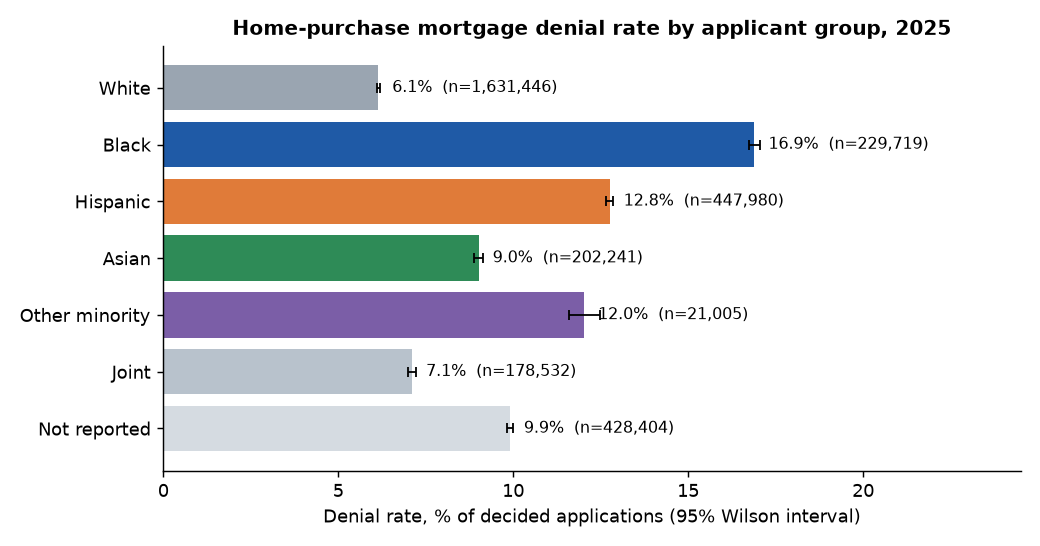

In [4]:
cols = ['applicant_group', 'applications', 'approval_rate', 'denial_rate', 'denial_ci_low', 'denial_ci_high', 'approval_air', 'denial_ratio', 'share_dti_50_plus', 'share_ltv_over_95']
display(T('rates_by_group')[cols])
display(Image(filename='reports/figures/01_denial_rate_by_group.png'))

## 3. Underwriting: the debt-to-income cliff
HMDA reports DTI from 36% to 49% as exact values and other values in bands (`sql/06_dti_profile.sql`).

,loan_type,dti_value,dti_band,applications,denial_rate,share_of_denials_citing_dti
0,Conventional,15,1 <20%,102269,0.0879,0.3006
1,Conventional,25,2 20-29%,326495,0.0382,0.0242
2,Conventional,33,3 30-35%,339192,0.0383,0.0355
3,Conventional,36,4 36-39%,65630,0.0396,0.0528
4,Conventional,37,4 36-39%,69233,0.0392,0.0608
5,Conventional,38,4 36-39%,72114,0.0406,0.0658
6,Conventional,39,4 36-39%,75611,0.0403,0.0670
7,Conventional,40,5 40-44%,78449,0.0411,0.0677
8,Conventional,41,5 40-44%,81347,0.0414,0.0742
9,Conventional,42,5 40-44%,88159,0.0417,0.0846


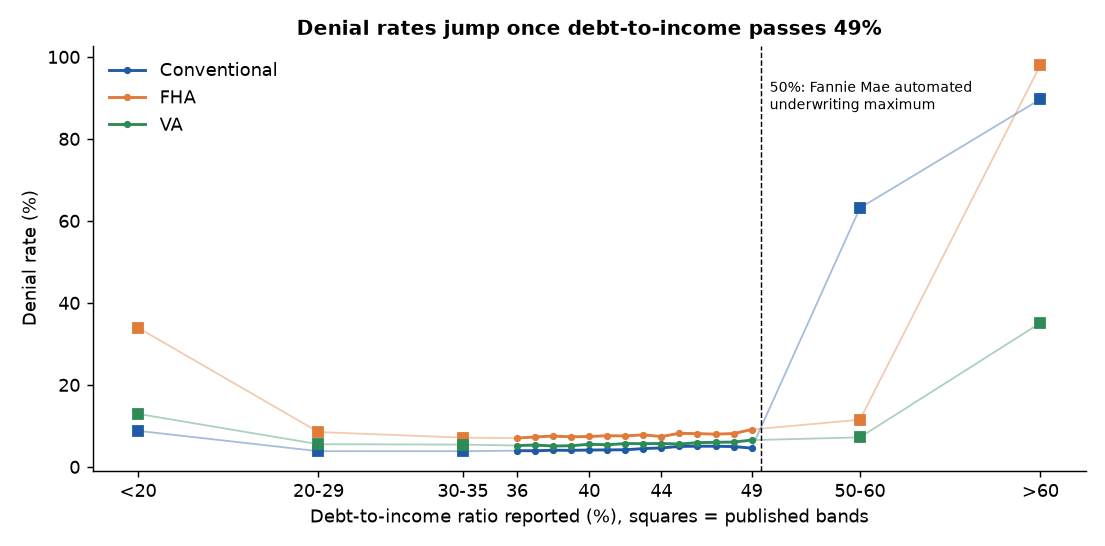

In [5]:
dti = data.query('06_dti_profile.sql')
display(dti[dti.loan_type == 'Conventional'])
display(Image(filename='reports/figures/03_denial_by_dti.png'))

Denial reasons (up to four per application), from an `unnest` over the four reason columns.

applicant_group,White,Black,Hispanic,Asian
reason,,,,
Debt-to-income ratio,0.3864,0.4605,0.4583,0.4906
Collateral,0.1903,0.1139,0.1547,0.1556
Credit history,0.1791,0.2787,0.1652,0.0831
Other,0.1268,0.1221,0.1307,0.1286
Insufficient cash,0.1181,0.1290,0.1204,0.1181
Credit application incomplete,0.1069,0.0590,0.0697,0.0874
Unverifiable information,0.0898,0.0938,0.1161,0.1248
Employment history,0.0517,0.0497,0.0534,0.0597
Mortgage insurance denied,0.0017,0.0015,0.0016,0.0014


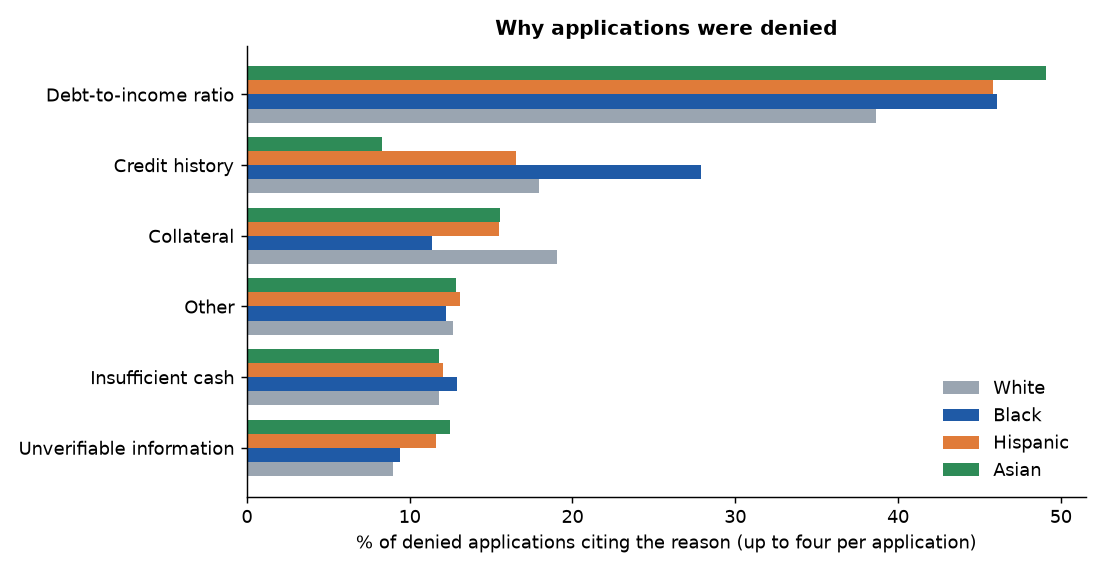

In [6]:
r = T('denial_reasons')
display(r.pivot(index='reason', columns='applicant_group', values='share_of_denials')[['White', 'Black', 'Hispanic', 'Asian']].sort_values('White', ascending=False))
display(Image(filename='reports/figures/04_denial_reasons.png'))

## 4. The gap ladder
Linear probability model of denial. Specification 1: group indicators only. 2: plus DTI band, LTV band, log income, log loan amount, log property value, conforming flag, loan type, age, sex, application channel and tract income band. 3 and 4: plus absorbed lender x state or lender x county fixed effects. Errors clustered by lender.

In [7]:
lad = T('denial_gap_ladder')
lad.assign(gap_pp=lad.coef * 100, ci_low_pp=lad.ci_low * 100, ci_high_pp=lad.ci_high * 100).pivot(index='spec', columns='group', values='gap_pp').round(2)

group,Asian,Black,Hispanic,Other minority
spec,,,,
1 Raw gap,2.9100,10.4000,6.4500,5.3400
2 + underwriting controls,2.5600,5.8400,3.0900,2.9100
3 + lender x state,1.6500,4.8400,2.0700,2.5300
4 + lender x county,1.5000,4.4800,1.9000,2.3800


,n,clusters,absorbed_groups,r2_within,regressors
1 Raw gap,"2,396,022.0000","2,461.0000",0.0000,0.0172,5.0000
2 + underwriting controls,"2,396,022.0000","2,461.0000",0.0000,0.2167,39.0000
3 + lender x state,"2,391,463.0000","2,382.0000","16,493.0000",0.2066,38.0000
4 + lender x county,"2,305,704.0000","2,319.0000","122,949.0000",0.2083,38.0000


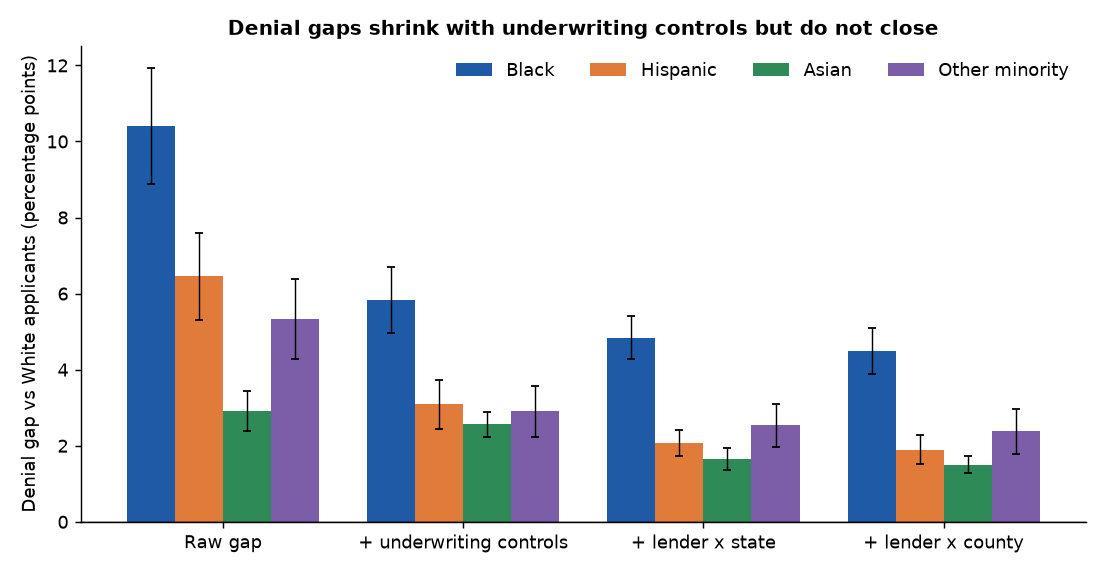

In [8]:
display(pd.DataFrame(results['gap_ladder']['fits']).T)
display(Image(filename='reports/figures/02_denial_gap_ladder.png'))

Robustness: logit with the same controls and state dummies on a random sample; average marginal effects with delta-method intervals.

In [9]:
T('logit_marginal_effects')

,group,ame,ci_low,ci_high,odds_ratio,n,converged
0,Black,0.0495,0.0469,0.0521,2.1662,600000,True
1,Hispanic,0.0234,0.0216,0.0252,1.5204,600000,True
2,Asian,0.0256,0.0229,0.0283,1.5720,600000,True
3,Other minority,0.0279,0.0206,0.0352,1.6271,600000,True


## 5. Oaxaca-Blinder decomposition
Pooled coefficients with a group indicator, so explained + unexplained equals the raw gap.

,group,raw_gap,explained,unexplained,unexplained_ci_low,unexplained_ci_high,n,Debt-to-income,Loan type,Income and loan size,Loan-to-value,Age and sex,Neighbourhood income,Application channel
0,Black,0.1040,0.0456,0.0585,0.0497,0.0672,1761985,0.0380,-0.0056,0.0052,0.0029,0.0028,0.0020,0.0003
1,Hispanic,0.0645,0.0321,0.0324,0.0258,0.0390,1970559,0.0274,-0.0025,0.0031,-0.0003,0.0010,0.0012,0.0021
2,Asian,0.0291,0.0038,0.0253,0.0221,0.0285,1738946,0.0068,0.0044,-0.0085,-0.0021,0.0014,0.0001,0.0018


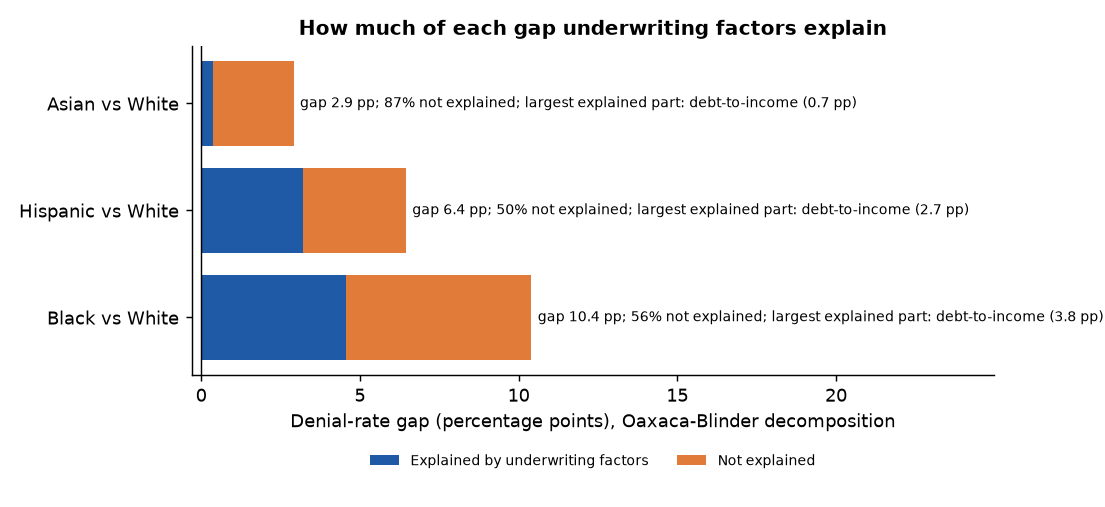

In [10]:
display(T('oaxaca_blinder'))
display(Image(filename='reports/figures/05_gap_decomposition.png'))

## 6. Pricing and neighbourhoods

group,Asian,Black,Hispanic,Other minority
spec,,,,
1 Raw gap,-13.0000,3.7000,16.6000,-0.3000
2 + underwriting controls,-8.2000,-3.4000,10.6000,-2.6000
3 + lender x state,-1.9000,1.6000,8.0000,0.3000


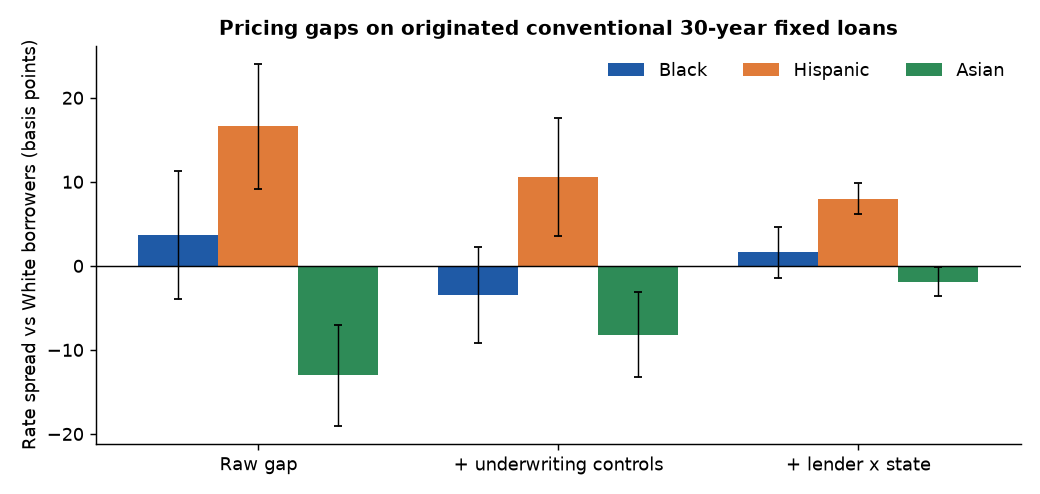

In [11]:
p = T('pricing_gaps')
display(p.pivot(index='spec', columns='group', values='coef').round(1))
display(Image(filename='reports/figures/07_pricing_gaps.png'))

,tract_minority_band,raw_denial_rate,applications,raw_gap,coef,ci_low,ci_high
0,1 <10%,0.0661,260623,0.0000,NaN,NaN,NaN
1,2 10-30%,0.0604,967494,-0.0057,-0.0064,-0.0086,-0.0043
2,3 30-50%,0.0781,543413,0.0120,-0.0058,-0.0082,-0.0033
3,4 50-80%,0.1009,421319,0.0348,-0.0040,-0.0073,-0.0008
4,5 80%+,0.1376,203173,0.0715,0.0050,0.0009,0.0090


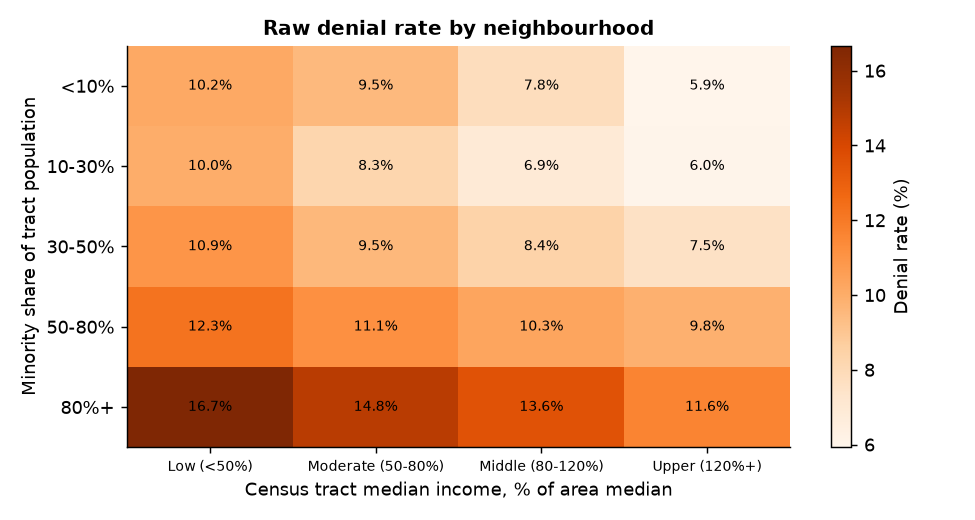

In [12]:
display(T('neighbourhood_gaps'))
display(Image(filename='reports/figures/06_denial_by_neighbourhood.png'))

## 7. Lender screen
Within each large lender: controls plus county fixed effects, errors clustered by county. Screening statistics, not findings.

,lender_name,applications,denial_rate,raw_gap_black,adj_gap_black,ci_low_black,ci_high_black,adj_gap_hispanic,screen
0,United Wholesale Mortgage,189577,0.0856,0.1002,0.0334,0.0275,0.0393,0.0136,Gap above zero: review files
1,ROCKET MORTGAGE,110482,0.1263,0.0905,0.0384,0.0301,0.0466,0.0169,Gap above zero: review files
2,"CROSSCOUNTRY MORTGAGE, LLC",67674,0.0255,0.0442,0.0273,0.0211,0.0335,0.0086,Gap above zero: review files
3,"DHI Mortgage Company, LTD.",62249,0.1644,0.1644,0.0871,0.0782,0.0960,0.0446,Gap above zero: review files
4,GUILD MORTGAGE COMPANY,49321,0.0303,0.0572,0.0339,0.0255,0.0423,0.0109,Gap above zero: review files
...,...,...,...,...,...,...,...,...,...
68,"Synergy One Lending, Inc.",5347,0.0597,0.0798,0.0298,-0.0055,0.0651,0.0413,Gap above zero: review files
69,TOWNE MORTGAGE COMPANY,5231,0.0386,0.0444,0.0246,0.0029,0.0462,0.0047,Gap above zero: review files
70,"VANDERBILT MORTGAGE AND FINANCE, INC",5183,0.0162,0.0304,0.0187,0.0046,0.0328,0.0132,Gap above zero: review files
71,FIRST NATIONAL BANK OF PA,5124,0.1042,0.1122,0.0463,0.0192,0.0734,0.0566,Gap above zero: review files


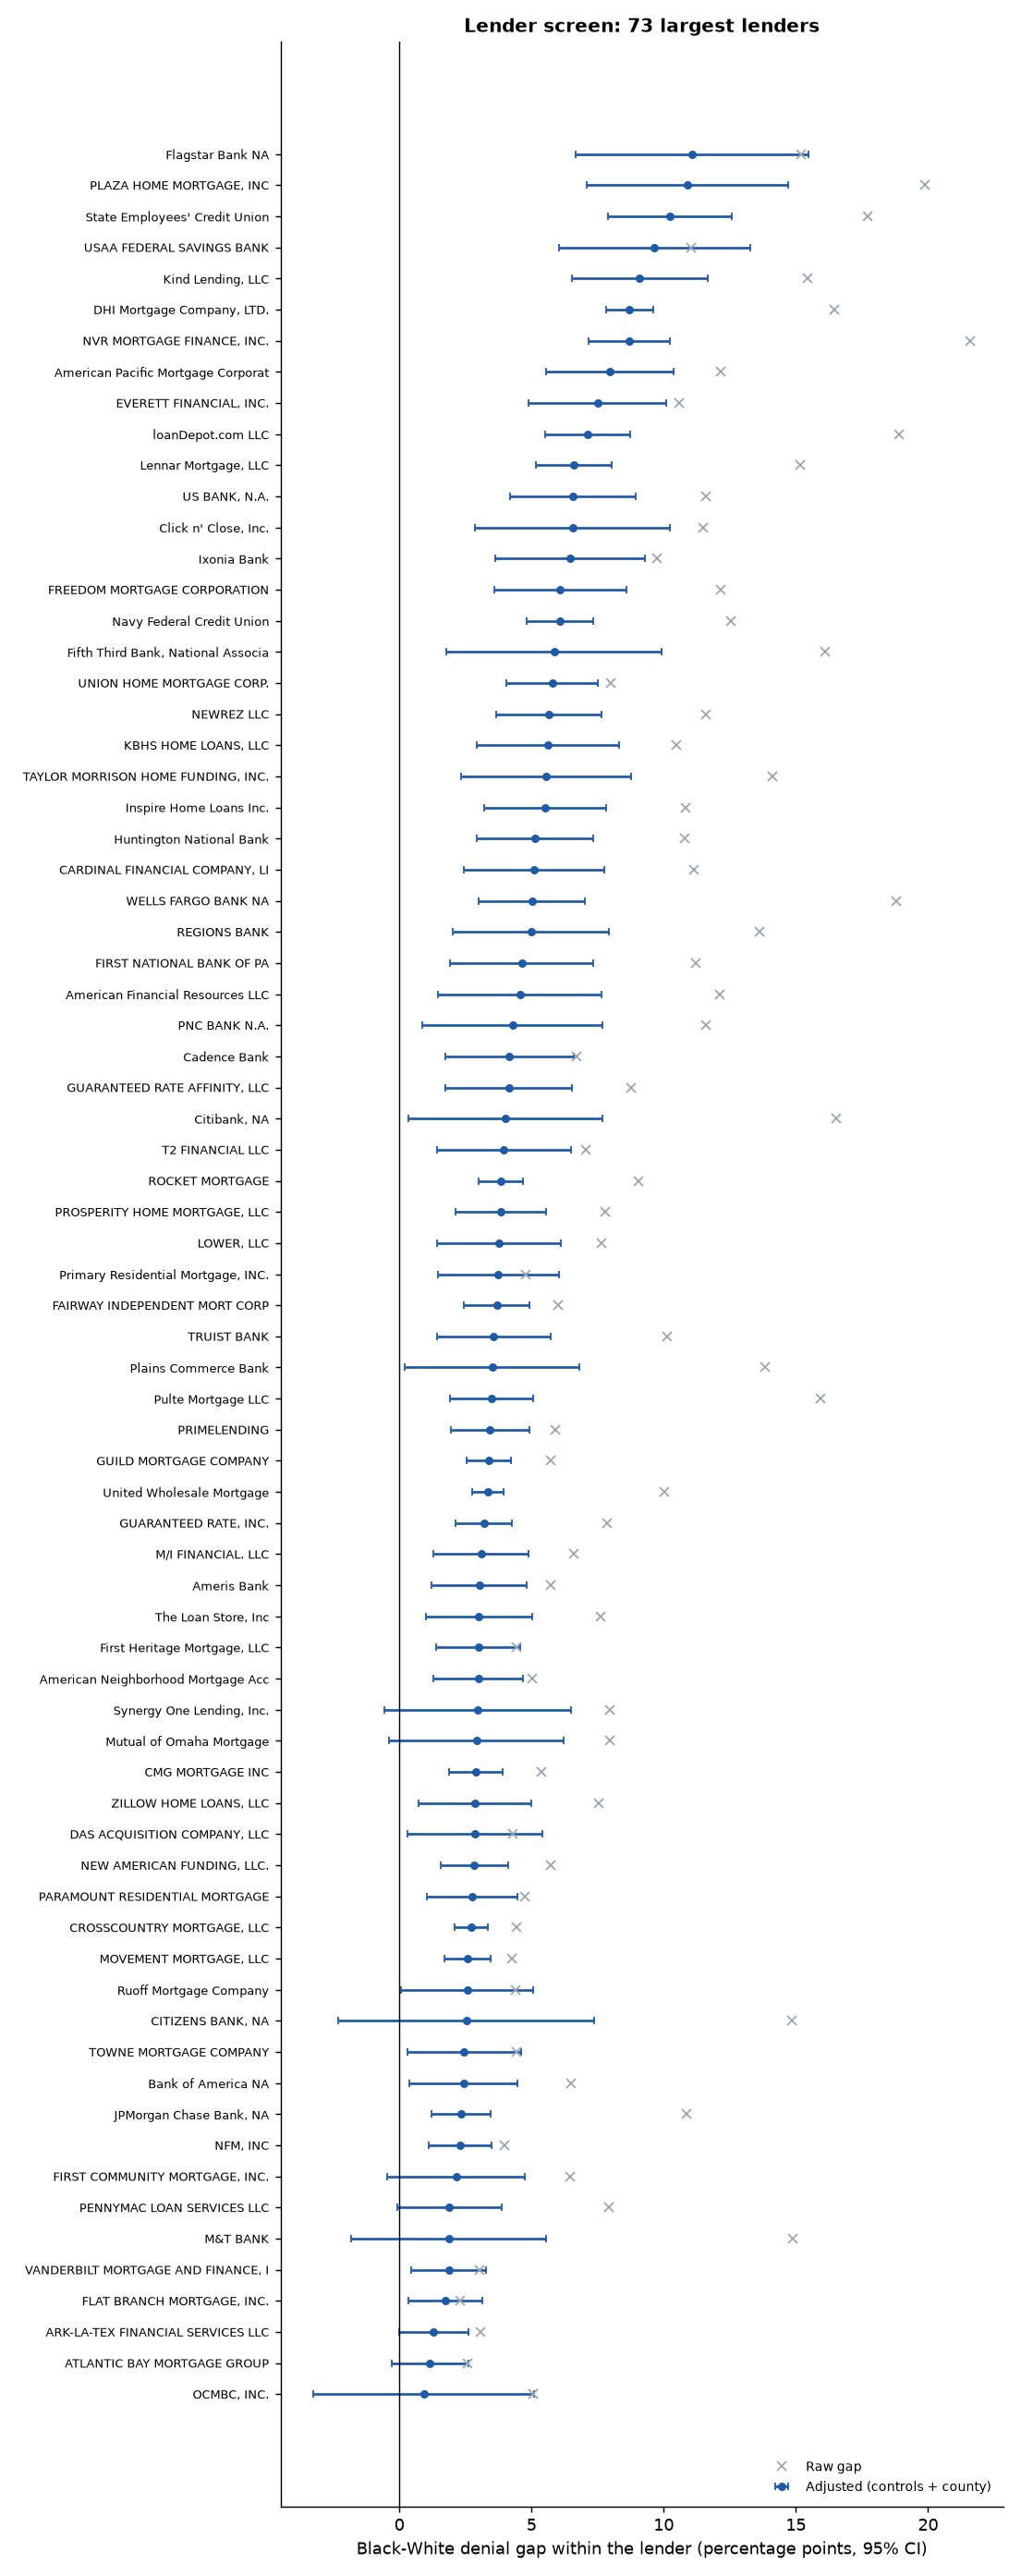

In [13]:
s = T('lender_screen')
display(s[['lender_name', 'applications', 'denial_rate', 'raw_gap_black', 'adj_gap_black', 'ci_low_black', 'ci_high_black', 'adj_gap_hispanic', 'screen']])
display(Image(filename='reports/figures/08_lender_screen.png'))

## 8. Policy simulator
What a 44% DTI cap would do to approvals by group (same logic as the Excel model).

In [14]:
grid = data.query('13_policy_grid.sql')
fairlending.simulate_policy(grid, dti_max=5)[['applicant_group', 'approved', 'approved_after', 'share_lost', 'air', 'air_after', 'volume_lost']]

,applicant_group,approved,approved_after,share_lost,air,air_after,volume_lost
0,Asian,"184,013.0000","126,504.0000",0.3125,0.9694,0.9318,"30,661,765,000.0000"
1,Black,"190,911.0000","101,819.0000",0.4667,0.8854,0.6603,"32,236,880,000.0000"
2,Hispanic,"390,836.0000","211,627.0000",0.4585,0.9295,0.7037,"66,850,445,000.0000"
3,Other minority,"18,479.0000","11,130.0000",0.3977,0.9373,0.7893,"2,836,995,000.0000"
4,White,"1,531,247.0000","1,095,177.0000",0.2848,1.0000,1.0000,"169,623,660,000.0000"


## 9. Memo

In [15]:
display(Markdown(open('reports/memo.md').read()))

# Memo: fair-lending screen of 2025 home-purchase mortgage decisions

**To:** Chief Compliance Officer · **Data:** HMDA 2025, 3,139,327 decided home-purchase applications (core sample)

**What we found**

- **3,139,327 home-purchase applications reached a credit decision in 2025** in the core sample (first-lien, owner-occupied, site-built 1-4 unit homes; 72% of all 4,358,716 decided home-purchase applications reported under HMDA). 91.3% were approved and 8.7% denied; 2,787,322 loans closed for $1.13 trillion.
- **Black applicants were denied 2.8 times as often as White applicants** (16.9% against 6.1%); Hispanic applicants 12.8% (2.1x) and Asian applicants 9.0% (1.5x). Every group still passes the four-fifths screen on approval rates (lowest ratio 0.89, Black), because approval rates near 90% make large denial gaps look small as approval ratios. Denial-rate ratios are the better screen here.
- **Debt-to-income above 49% is close to an automatic denial for conventional loans.** The conventional denial rate is 4.6% at a reported DTI of 49% and 63.1% at 50-60% (90% above 60%), matching Fannie Mae's 50% maximum for automated underwriting; DTI is cited in 86% of those denials. FHA has no cliff at 50% (9.1% at 49%, 11.5% at 50-60%). 26% of Black and 22% of Hispanic applicants report DTI of 50% or more, against 10% of White applicants.
- **Underwriting factors explain about half of the Black-White gap.** Adding DTI, loan-to-value, income, loan size, loan type, age, sex and neighbourhood income cuts the Black-White gap from 10.4 pp to 5.8 pp (44% explained) and the Hispanic gap from 6.4 pp to 3.1 pp. Comparing applicants at the same lender in the same county leaves 4.5 pp for Black applicants (95% CI 3.9 to 5.1), 1.9 pp for Hispanic and 1.5 pp for Asian applicants. A logit model on 600,000 applications gives the same picture (Black marginal effect 5.0 pp, odds ratio 2.17).
- **The largest explained part is debt-to-income.** In the Oaxaca-Blinder decomposition it accounts for 3.8 pp of the 10.4 pp Black-White gap; debt-to-income accounts for 2.7 pp of the 6.4 pp Hispanic-White gap.
- **Credit history is the factor HMDA cannot control for.** It is cited in 28% of denials of Black applicants and 18% of denials of White applicants. The public data has no credit scores, so part of the unexplained gap may be credit differences; a lender can close this question with its own score data, the public file cannot.
- **Pricing: at the same lender in the same state, Hispanic borrowers pay 8.0 bps more (95% CI 6.1 to 9.8 bps)** than comparable White borrowers on 1,206,195 originated conventional 30-year fixed loans (rate spread over the average prime offer rate, controlling for points paid). Black borrowers pay about the same (+1.6 bps, 95% CI -1.4 to 4.6 bps); Asian borrowers pay 1.9 bps less (95% CI -3.6 to -0.1 bps).
- **Neighbourhood: applications in tracts that are 80%+ minority are denied at 13.8%** against 6.6% in tracts under 10% minority. After applicant controls and lender x state effects the difference is 0.5 pp (95% CI 0.1 to 0.9): most of the raw gap comes from who applies there, and a small part is tied to the location.
- **Lender screen: 64 of the 73 largest lenders show a Black-White denial gap whose 95% interval is above zero after controls and county effects**, and 48 show one for Hispanic applicants (median adjusted gaps 3.7 pp and 1.9 pp). These are screening results that point to files to review, not findings.
- **A 44% DTI cap would remove 769,229 approvals (33.2%) and $302.2 billion of loans,** falling on 46.7% of Black and 45.9% of Hispanic approvals against 28.5% of White approvals. The Black approval-rate ratio would fall from 0.885 to 0.660, and Black, Hispanic and Other minority applicants would fall below the four-fifths screen.

**What to do**

1. Track denial-rate ratios and adjusted gaps every quarter next to the four-fifths approval ratio, which passes for every group even though Black applicants are denied 2.8 times as often.
2. Before any guideline change, run the Excel simulator: a 44% DTI cap removes 46.7% of Black approvals and an LTV cap at 95% removes 61.8%, against 28.5% and 27.3% for White applicants. Document a business need and a less discriminatory alternative for any cap that lowers a group's ratio.
3. Offer debt-payoff and loan-size counselling at application to applicants whose DTI is just above 49%, where conventional denial rates jump; FHA is an alternative product for many of them.
4. Rerun the gap ladder on internal data with credit scores and full DTI detail. The remaining gap after scores is the figure regulators examine; the public data stops one step short of it.
5. Review pricing exceptions and lender credits for Hispanic borrowers, where the rate-spread gap remains within lender and state.
6. Use the lender screen as a peer benchmark: lenders with an interval above zero should sample denied files of comparable Black, Hispanic and White applicants for review.

**Caveats:** no credit scores in HMDA; adjusted gaps are screens, not findings; policy-cap losses are upper bounds; the revenue rate is an assumption.
